In [1]:
! pip install --no-deps astropy-healpix

Defaulting to user installation because normal site-packages is not writeable


In [2]:
import healpy as hp
import numpy as np
from astropy import units as u

from astropy_healpix import pixel_resolution_to_nside
import pandas as pd
import ROOT

cling::DynamicLibraryManager::loadLibrary(): libOpenGL.so.0: cannot open shared object file: No such file or directory
Error in <AutoloadLibraryMU>: Failed to load library /cvmfs/sft.cern.ch/lcg/releases/ROOT/6.28.04-740f6/x86_64-el9-gcc11-opt/lib/libEve.socling JIT session error: Failed to materialize symbols: { (main, { _ZeqRK7TStringRKNSt7__cxx1112basic_stringIcSt11char_traitsIcESaIcEEE }) }


Welcome to JupyROOT 6.28/04


In [3]:
pixel_resolution_to_nside(0.9 * u.deg)

64

In [4]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

def plot_hpx_map(hpx_map, 
                 title="", 
                 label="", 
                 output_name="", 
                 logNorm=False, 
                 figPath=None):

    # ---- Determine min/max safely ----
    positive = hpx_map[hpx_map > 0]

    if positive.size == 0:
        vmin, vmax = 1, 10  # fallback for empty map
    else:
        vmin = float(positive.min())
        vmax = float(positive.max())

        # avoid degenerate case
        if vmax <= vmin:
            vmax = vmin * 10

    # ---- Plot ----
    plt.figure(figsize=(10, 5))

    if logNorm:
        hp.mollview(
            hpx_map,
            title=title,
            unit=label,
            norm='log',        # <-- IMPORTANT
            min=vmin,
            max=vmax,
            cmap="viridis",
            cbar=True,
            notext=False,
            badcolor="black"
        )
    else:
        hp.mollview(
            hpx_map,
            title=title,
            unit=label,
            min=vmin,
            max=vmax,
            cmap="viridis",
            cbar=True,
            notext=False,
            badcolor="black"
        )

    # ---- Save ----
    if figPath:
        figName = figPath + output_name
        plt.savefig(figName, dpi=200, bbox_inches="tight")
        print(f"Saved plot to {figName}")

    return plt.gcf()

In [5]:
def plot_counts_map_hpx(hpx_counts_map, energy=None, figPath=None):
    """
    Replacement for your plot_counts_map but using HEALPix.
    """
    title = "γ-rays Counts, 9 years"
    label = "Counts"
    output_name = "CountMap"

    if energy:
        title += f" | Energy : {energy} GeV"
        output_name += f"-{energy}"

    output_name += ".png"

    return plot_hpx_map(
        hpx_counts_map,
        title=title,
        label=label,
        output_name=output_name,
        logNorm=True,
        figPath=figPath
    )

In [6]:
# Load the table once globally
PATH_EFFAREA = "/home/users/l/lebrun/results/effArea/effectiveArea_weighted.npz"
PATH_BINS = "/home/users/l/lebrun/results/effArea_bins_info_HET.npz"
# Load the effective area table
EFF_AREA_NPZ = np.load(PATH_EFFAREA)
# Get bins edges and centers
ENERGY_BINS_EDGES = EFF_AREA_NPZ['E_bins_edge']
ENERGY_BINS_CENTERS = np.sqrt(ENERGY_BINS_EDGES[:-1] * ENERGY_BINS_EDGES[1:])  # GeV

energy_bin = 6
energy = ENERGY_BINS_CENTERS[energy_bin]
energy_exposure_map_str = f"{energy:.1f}"

resPath = "/home/users/l/lebrun/results/"
verbose = True



In [7]:
PSF_path = "/home/users/l/lebrun/results/PSF/exp0.0/script/resolution_per_bin_w.csv"
PSF_infos_path = "/home/users/l/lebrun/results/PSF/exp0.0/script/infos_bins.npz"
df_PSF = pd.read_csv(PSF_path)
print(df_PSF.head())

PSF_infos = np.load(PSF_infos_path)
print([key for key in PSF_infos.keys()])


def find_PSF_Ebin(energy, infos) :
    E_edges = np.asarray(infos["E_bins_edge"])
    # searchsorted gives the position where energy would be inserted
    idx = np.searchsorted(E_edges, energy) - 1

    # Out-of-range protection
    if idx < 0 or idx >= len(E_edges) - 1:
        return -1  # or raise ValueError("Energy outside bins")

    return idx

PSF_Ebin = find_PSF_Ebin(energy, PSF_infos)
print(energy, PSF_Ebin)

   E_bin  theta_bin  angular_resolution
0      0          0            0.460173
1      0          1            0.711977
2      0          2            0.629419
3      0          3            0.572459
4      0          4            0.519339
['E_bins_edge', 'theta_bins_edge', 'E_bins_center', 'theta_bins_center']
4.466835921509632 1


In [8]:
# Compute required NSIDE
ang_resolution = df_PSF.angular_resolution[df_PSF.E_bin == 0].max()
print(ang_resolution)

0.7119772174314146


In [11]:
NSIDE = pixel_resolution_to_nside(ang_resolution * u.deg)
NPIX = hp.nside2npix(NSIDE)
print(
    "Approximate resolution at NSIDE {} is {:.2} deg".format(
        NSIDE, hp.nside2resol(NSIDE, arcmin=True) / 60
    )
)


Approximate resolution at NSIDE 64 is 0.92 deg


In [12]:


# Grid definition
lon_edges = np.linspace(-np.pi, np.pi, 720 + 1)
lon_centers = 0.5 * (lon_edges[:-1] + lon_edges[1:])
dlon = lon_edges[1] - lon_edges[0]

lat_centers = np.linspace(-np.pi/2, np.pi/2, 361)
dlat = lat_centers[1] - lat_centers[0]
lat_edges = np.zeros(len(lat_centers) + 1)
lat_edges[0] = lat_centers[0] - dlat
lat_edges[1:] = lat_centers


def load_and_process_df(dataFile):
    tree = None
    f = ROOT.TFile(dataFile, "READ") 

    tree = f.Get("DmlNtup")
    print(tree)
    print(type(tree))
    rdf = ROOT.RDataFrame(tree)
    df = rdf.AsNumpy(["celestialcoordBest_2", "celestialcoordBest_3", "tt_bgoTotalEcorr_GeV"])
    df = pd.DataFrame(df)

    df = df.rename(columns={"celestialcoordBest_2" : "lon", "celestialcoordBest_3" : "lat", 
                            "tt_bgoTotalEcorr_GeV" : "energy"})

    df['lon_deg'] = df['lon']*180/np.pi
    df['lat_deg'] = df['lat']*180/np.pi
    df['lon'] = np.where(df['lon'] > np.pi, df['lon'] - 2*np.pi, df['lon'])

    return df

In [13]:
import os
dirDir= "/home/users/l/lebrun/"
resultPath = dirDir + "results/"
figPath = dirDir + "figures/fluxMaps/"
dataPath = dirDir + "data/"
dataFile = dataPath + "DmlNtup_Data_9years_FullPhotonData_AllSky.root"
exposurePath = "/dpnc/beegfs/dampe/tryf/ForKimberly/filtered_cos_theta_bins/exposureMaps/"

figPath += energy_exposure_map_str + "GeV/"
try : 
    if not os.path.exists(figPath):
        os.makedirs(figPath)
except FileExistsError as e:
    pass

df = load_and_process_df(dataFile)

print(df['lon'].head())

# Your event coordinates (degrees → radians → HEALPix angles)
lon = df['lon'].values      # φ
lat = df['lat'].values
theta = np.pi/2 - lat                   # θ = colatitude
phi = lon                               # φ = longitude

# Convert angles to HEALPix pixel index
ipix = hp.ang2pix(NSIDE, theta, phi)

# Count map
count_map = np.zeros(NPIX, dtype=float)
np.add.at(count_map, ipix, 1)

Name: DmlNtup Title: DmlNtup
<class cppyy.gbl.TTree at 0x19df8270>
0    1.597004
1    1.374540
2    0.397627
3   -0.176473
4    0.560877
Name: lon, dtype: float64


Saved plot to /home/users/l/lebrun/figures/fluxMaps/4.5GeV/CountMap-4.5.png


<Figure size 720x360 with 0 Axes>

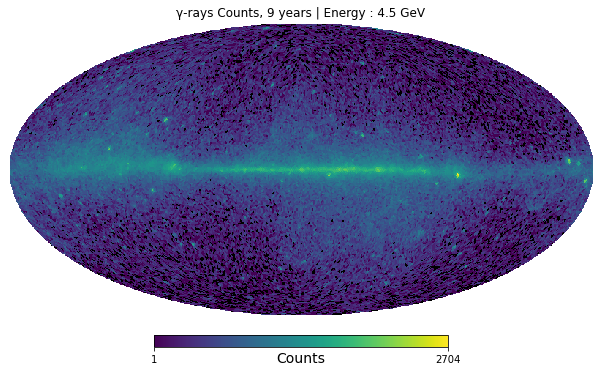

In [14]:
# Plot with HEALPix
figName = figPath + "CountMap"
fig = plot_counts_map_hpx(count_map, energy=energy_exposure_map_str, figPath=figPath)